This notebook covers a general EDA of the data used, an overview of the methods chosen for the anomaly detection task, their efficacy and some considerations on these. It is to be considered a birdseye view of the work conducted. The validated results are not found here but in the "experiments" section. This notebook can be useed to play around with the methods and the dataset. The average execution time is 30min.

In [1]:
#utils
import pandas as pd
import numpy as np
import contextlib
import os
import warnings

#visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

#machine learning
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve, auc
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import roc_curve, auc, precision_recall_curve, precision_score, recall_score, f1_score, roc_auc_score


warnings.filterwarnings("ignore")

#it's important that eager execution is enabled
#it comes as a default setting in tensorflow 2.0
if tf.executing_eagerly():
    print("Eager execution is enabled.")
else:
    print("Eager execution is not enabled.")


Eager execution is enabled.


In [2]:
df = pd.read_csv('SimulationData.csv')
df = df.head(1000)

df.head()

,isghost,chi2,nb_hits,qop,tx,ty,x,y,z,trk_best_pt,...,trk_kalman_ipx,trk_kalman_ipy,trk_ndof,trk_ndofT,trk_ndofV,trk_velo_docaz,trk_velo_ip,trk_velo_ip_chi2,trk_velo_ipx,trk_velo_ipy
0,0,5.864667,23,0.000023,-0.028342,-0.003546,0.000634,-0.005067,78.771744,1268.343506,...,-0.009011,-0.009870,10.0,3.809383e+09,0.0,0.053306,0.056174,0.229229,-0.011182,-0.055074
1,0,9.498068,22,-0.000089,-0.035880,-0.009850,-0.019085,0.069519,80.973526,418.299805,...,0.052025,0.087872,12.0,3.809383e+09,0.0,0.006958,0.108953,0.530859,0.106834,0.021767
2,0,8.184366,22,-0.000057,-0.016312,-0.009838,-0.017012,0.028208,92.175171,334.801575,...,0.031604,0.027265,8.0,3.809383e+09,0.0,0.018347,0.206216,3.245677,0.166305,0.121998
3,0,86.617691,22,-0.000032,-0.019891,-0.019328,-1.889721,1.944762,120.151199,869.915710,...,0.000000,0.000000,10.0,3.809383e+09,0.0,2.375821,2.491225,460.366547,-1.065801,2.252785
4,0,7.774436,27,-0.000066,-0.018290,-0.012823,1.265772,-1.805411,-33.804581,337.069244,...,1.973482,-1.313249,18.0,3.809383e+09,0.0,2.292284,2.458901,270.415924,2.037640,-1.377404


In [55]:
df.columns

Index(['isghost', 'chi2', 'nb_hits', 'qop', 'tx', 'ty', 'x', 'y', 'z',
       'trk_best_pt', 'trk_best_qop', 'trk_chi2', 'trk_chi2T', 'trk_chi2V',
       'trk_first_qop', 'trk_kalman_docaz', 'trk_kalman_ip',
       'trk_kalman_ip_chi2', 'trk_kalman_ipx', 'trk_kalman_ipy', 'trk_ndof',
       'trk_ndofT', 'trk_ndofV', 'trk_velo_docaz', 'trk_velo_ip',
       'trk_velo_ip_chi2', 'trk_velo_ipx', 'trk_velo_ipy'],
      dtype='object')

In [3]:
#this gives us the duimension of the dataset we're working with.
df.shape

(1000, 28)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 28 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   isghost             1000 non-null   int64  
 1   chi2                1000 non-null   float64
 2   nb_hits             1000 non-null   int64  
 3   qop                 1000 non-null   float64
 4   tx                  1000 non-null   float64
 5   ty                  1000 non-null   float64
 6   x                   1000 non-null   float64
 7   y                   1000 non-null   float64
 8   z                   1000 non-null   float64
 9   trk_best_pt         1000 non-null   float64
 10  trk_best_qop        1000 non-null   float64
 11  trk_chi2            1000 non-null   float64
 12  trk_chi2T           1000 non-null   float64
 13  trk_chi2V           1000 non-null   float64
 14  trk_first_qop       1000 non-null   float64
 15  trk_kalman_docaz    1000 non-null   float64
 16  trk_kal

In [5]:
df.isghost.describe()

count    1000.000000
mean        0.033000
std         0.178726
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         1.000000
Name: isghost, dtype: float64

# Visualize all the data points where ghost=1 and any feature has an outlier value

qop stands for "charge-to-over-momentum" ratio, is a measure of the electric charge of a particle relative to its momentum

In [6]:
target_feature = "isghost"
columns = df.drop(columns=target_feature).columns
#instantiate two more datasets one to contain the normal data
#and the other to hold the anomalous instances
train_normal_data = df[df[target_feature] == 0].drop(columns=target_feature)
anomalous_data = df[df[target_feature] == 1].drop(columns=target_feature)

In [7]:
#also instantiate a dataframe to carry all the features
#and a second one to instead contain the target variable
def get_normal_data(df):
    df = df.sample(frac=1)
    features = df.drop([target_feature], axis=1)
    label = df[target_feature]

    #the stratify parameter here is set to be "isghost" meaning that the 
    #proportions of ghost and normal tracks in both train and test datasets
    #will be kept the same...
    x_train, x_test, y_train, y_test = train_test_split(
        features, label, test_size=0.2, stratify=label
    )

    #remember that at least for the autoencoders we're gonna use just the 
    #normal instances during the training phase so we have to filter those in x_train
    train_index = y_train[y_train == 0].index
    train_normal_data = x_train.loc[train_index]

    return train_normal_data, x_train, y_train, x_test, y_test

In [8]:
train_normal_data, x_train, y_train, x_test, y_test = get_normal_data(df)

train_normal_data.head()

,chi2,nb_hits,qop,tx,ty,x,y,z,trk_best_pt,trk_best_qop,...,trk_kalman_ipx,trk_kalman_ipy,trk_ndof,trk_ndofT,trk_ndofV,trk_velo_docaz,trk_velo_ip,trk_velo_ip_chi2,trk_velo_ipx,trk_velo_ipy
878,31.462355,28,-0.000072,0.036428,0.018207,-0.009983,0.019973,-24.124123,561.591980,-0.000072,...,-0.066528,0.029624,24.0,3.809383e+09,0.0,0.050677,0.254242,2.308944,0.199744,0.157625
990,14.850861,24,0.000251,0.033254,-0.166913,0.028597,0.005697,14.232719,665.315491,0.000252,...,0.005416,-0.005597,14.0,3.809383e+09,0.0,0.102901,0.102914,0.082461,0.097758,0.036631
682,17.525574,23,0.000197,-0.034692,-0.063635,-0.039253,0.021400,91.202988,366.505280,0.000197,...,-0.054104,0.040662,10.0,3.809383e+09,0.0,0.243323,0.248481,3.605134,0.184774,-0.167104
73,15.913944,23,-0.000030,-0.022539,-0.006275,-0.008192,0.029427,30.989197,787.724548,-0.000030,...,-0.016490,0.021303,10.0,3.809383e+09,0.0,0.068023,0.076721,0.408668,0.015718,0.075116
707,10.317247,24,-0.000390,-0.048576,0.172683,-0.013416,-0.003774,-44.855991,451.013214,-0.000391,...,-0.007762,0.026465,14.0,3.809383e+09,0.0,0.190518,0.191361,0.423591,0.172061,0.090464


This is to show the distribution of the features before standardization. Given the number of the features, it would be not easy to plot them all, therefore only the 12 more correlated to the target variable will be considered. 

In [9]:
corr = df.corr().round(3)

correlation_with_target = corr[target_feature].abs().sort_values(ascending=False)
top_12_features = correlation_with_target[1:13]
top_12_feature_names = top_12_features.index.tolist() + [target_feature]

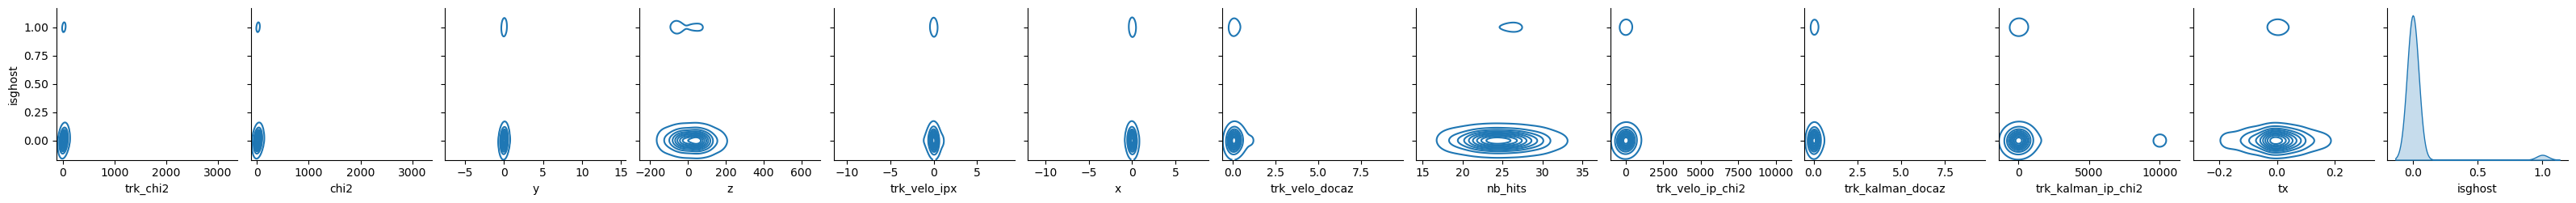

In [10]:
sns.pairplot(df, x_vars=top_12_feature_names, y_vars="isghost", kind='kde')

plt.savefig("images/original_data_pairplot.png", dpi=300)

In [11]:
"""from scipy.stats import iqr


def outliers(data):
    
    n_25 = np.percentile(25)
    n_75 = np.percentile(75)

    Iqrt = n_75 -n_25

    lower = n_25 + Iqrt

    upper = n_75 + Iqrt

    outliers = np.where((data < lower) | (data > upper))

    return outliers

outliers(df)"""

'from scipy.stats import iqr\n\n\ndef outliers(data):\n    \n    n_25 = np.percentile(25)\n    n_75 = np.percentile(75)\n\n    Iqrt = n_75 -n_25\n\n    lower = n_25 + Iqrt\n\n    upper = n_75 + Iqrt\n\n    outliers = np.where((data < lower) | (data > upper))\n\n    return outliers\n\noutliers(df)'

In [12]:
import sys


def standardize_normalize(train_x, normal_train_data, test_data):
    #here I need to rescale the data as the featurea have different ranges 


    #Don't forget that testing data points represent real-world data.
    #Feature normalization (or data standardization) of the explanatory (or predictor) variables
    #is a technique used to center and normalise the data by subtracting the mean and dividing by the variance.
    #If you take the mean and variance of the whole dataset you'll be introducing future information
    #into the training explanatory variables (i.e. the mean and variance).

    #Therefore, you should perform feature normalisation over the training data.
    #Then perform normalisation on testing instances as well, but this time using the mean and variance
    #of training explanatory variables. In this way, we can test and evaluate
    #whether our model can generalize well to new, unseen data points.

    #creating a scaler and decing which columns to process


    non_zero_cols = train_x.columns[(train_x != 0).any()]

    # Calculate mean and standard deviation only for non-zero columns
    mean = train_x[non_zero_cols].mean()
    std = train_x[non_zero_cols].std() + sys.float_info.min

    # Standardize the non-zero columns in normal_train_data, train_x, and test_data
    normal_train_data[non_zero_cols] = (normal_train_data[non_zero_cols] - mean) / std
    train_x[non_zero_cols] = (train_x[non_zero_cols] - mean) / std
    test_data[non_zero_cols] = (test_data[non_zero_cols] - mean) / std

    # Create a scaler and apply Min-Max scaling to all columns
    scaler = MinMaxScaler()
    normal_train_data = scaler.fit_transform(normal_train_data)
    train_x = scaler.transform(train_x)
    test_data = scaler.transform(test_data)
    
    return train_x, normal_train_data, test_data

In [13]:
x_train, train_normal_data, x_test = standardize_normalize(x_train, train_normal_data, x_test)
print(x_train)

[[1.63318671e-02 6.47058824e-01 4.11455663e-01 ... 2.30886089e-04
  5.22774573e-01 3.18403485e-01]
 [7.64043100e-03 4.11764706e-01 7.70505318e-01 ... 8.21548677e-06
  5.16956207e-01 3.12229808e-01]
 [9.03988960e-03 3.52941176e-01 7.09989043e-01 ... 3.60518058e-04
  5.21920533e-01 3.01834350e-01]
 ...
 [6.22686873e-03 2.94117647e-01 3.77041909e-01 ... 9.16289977e-06
  5.15106687e-01 3.10367330e-01]
 [1.19531081e-02 5.29411765e-01 7.04484250e-01 ... 9.29905683e-04
  5.18287190e-01 3.28105908e-01]
 [4.17489080e-03 3.52941176e-01 7.94689339e-01 ... 1.08404209e-04
  5.11451260e-01 3.04732106e-01]]


The following plot shows the effect of standardization and normalization to the data distribution. As it can be seen while the range has been changed the distribution has not been changed.  

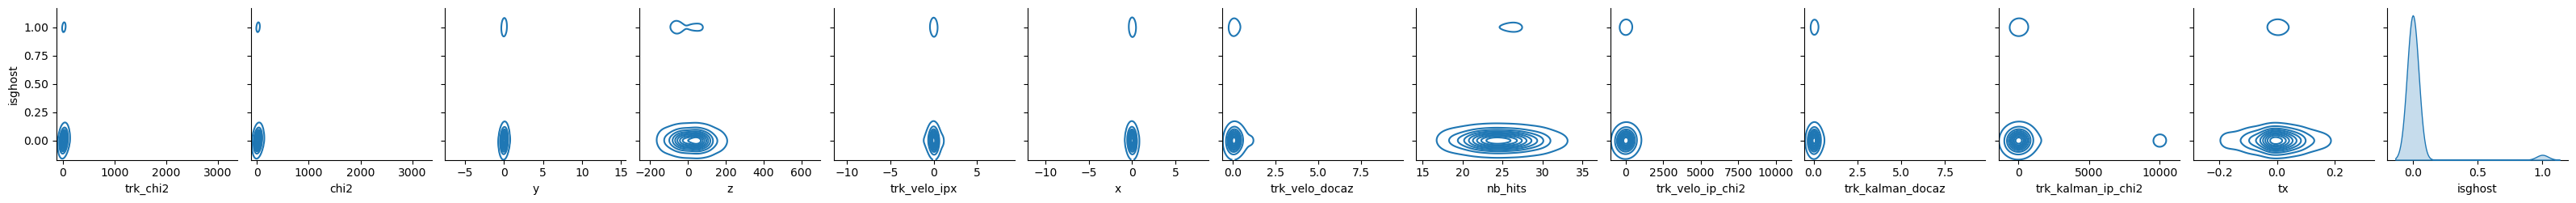

In [14]:
cols = pd.DataFrame(x_train, columns=columns)
trgt = pd.DataFrame(y_train, columns=['isghost'])

result = pd.concat([cols, trgt], axis=0)

sns.pairplot(df, x_vars=top_12_feature_names, y_vars="isghost", kind='kde')

plt.savefig("images/processed_data_pairplot.png", dpi=300)

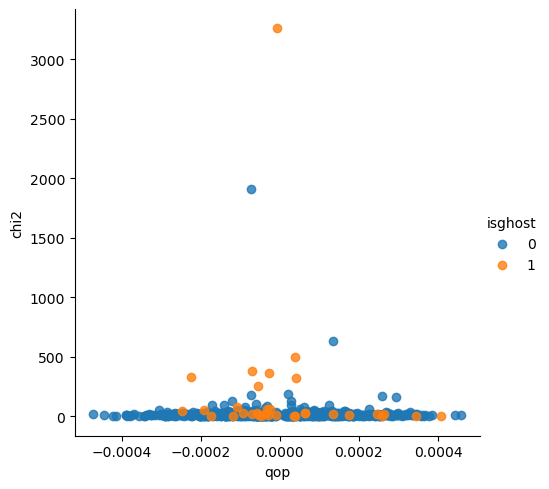

In [56]:
sns.lmplot(x='qop', y='chi2', hue='isghost', 
           data=df, 
           fit_reg=False)

# Visualization

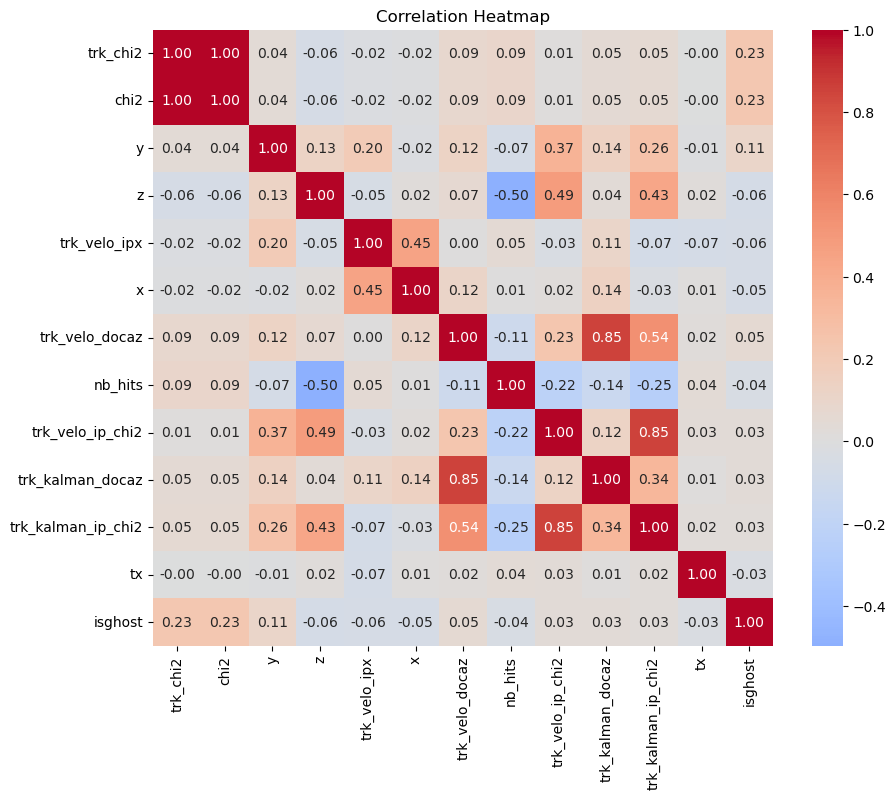

In [15]:
corr = df.corr().round(3)

correlation_with_target = corr[target_feature].abs().sort_values(ascending=False)
top_12_features = correlation_with_target[1:13]
top_12_feature_names = top_12_features.index.tolist() + [target_feature]

top_12_correlation_matrix = corr.loc[top_12_feature_names, top_12_feature_names]

plt.figure(figsize=(10, 8))
sns.heatmap(top_12_correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", center=0)
plt.title('Correlation Heatmap')
plt.show()

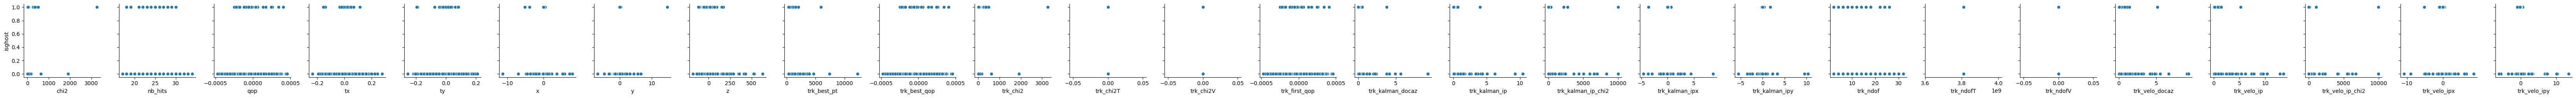

In [16]:
sns.pairplot(data=df, x_vars= df.drop(columns=target_feature).columns, y_vars=[target_feature])

plt.show()

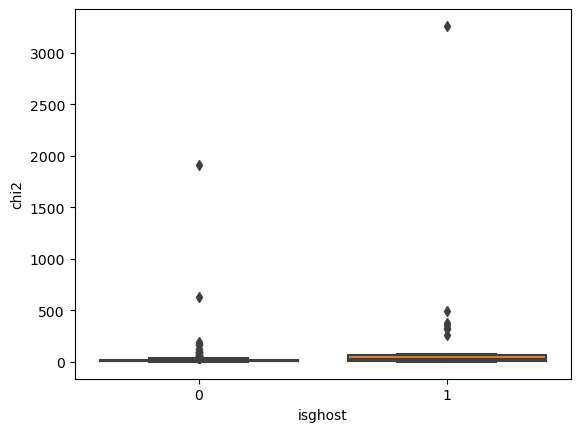

In [17]:
sns.boxplot(x=target_feature, y='chi2', data=df)

plt.show()

# Model Fitting

In [18]:
from models.AutoEncoder import Autoencoder
from models.ContractiveAutoEncoder import ContractiveAutoEncoder
from models.VariationalAutoencoder import VariationalAutoEncoder


#instantiate the contractive autoencoder
#the input dimension should match with the input features
#instead the latent dimensionis the desired compression rate
#such that higher latent_dim result in lower compression rate and more expressivity
#while instead lower latent dimension leads to less reconstruction quality
# but also less validatinon error (less model complexity)

#The latent space representation captures the most salient features of the input data
#a lower latent_dim may lead to a higher reconstruction error for anomalous inputs,
#setting latent_dim too low may also result in the loss of important information
#latent dimension should start small and then raised until diminishing returns 


#when performing anomaly detection using autoencoders these have to be trained using normal data
#such that the network learns to reproduce those instances, and that we can then perform the 
#detection using a threshold applied on the reconstruction error of any instance
input_dim = train_normal_data.shape[1]
latent_dim = 3
learning_rate = 0.001
epochs = 5

vae = VariationalAutoEncoder(input_dim=input_dim, latent_dim=latent_dim, learning_rate=learning_rate)
vae.build(input_shape=(train_normal_data.shape))
cae = ContractiveAutoEncoder(input_dim=input_dim, encoding_dim=latent_dim, lambda_= 0.01, learning_rate=learning_rate)
cae.build(input_shape=(train_normal_data.shape))
ae = Autoencoder(input_dim=input_dim, encoding_dim=latent_dim, learning_rate=learning_rate)
ae.build(input_shape=(train_normal_data.shape))


In [19]:
#start the training of the NN,
#assuming a convex loss function the higher the number of epochs the better the results will be.
#an higher batch size implies that a larger share of the training examples are processed together
#this eventually leads to fatser training and higher generalizion error (model doesn't learn underlying distribution but training data) 
history_cae, training_time_cae = cae.train(train_normal_data, epochs=epochs, batch_size=30)


Step: 0, Train Loss: 0.01677297055721283, Val Loss: 0.013308791443705559
Step: 0, Train Loss: 0.012087477371096611, Val Loss: 0.009664635173976421
Step: 0, Train Loss: 0.012089522555470467, Val Loss: 0.009580348618328571
Step: 0, Train Loss: 0.012035099789500237, Val Loss: 0.009618868120014668
Step: 0, Train Loss: 0.012185811996459961, Val Loss: 0.009649643674492836


In [20]:
history_ae, training_time_ae = ae.train(train_normal_data, epochs=epochs, batch_size=30, validation_split=0.2)

Epoch 1/5
21/21 [==============================] - 2s 29ms/step - loss: 0.0742 - val_loss: 0.0184
Epoch 2/5
21/21 [==============================] - 0s 16ms/step - loss: 0.0136 - val_loss: 0.0114
Epoch 3/5
21/21 [==============================] - 0s 16ms/step - loss: 0.0109 - val_loss: 0.0108
Epoch 4/5
21/21 [==============================] - 0s 16ms/step - loss: 0.0102 - val_loss: 0.0108
Epoch 5/5
21/21 [==============================] - 0s 21ms/step - loss: 0.0101 - val_loss: 0.0106


In [21]:
history_vae, training_time_vae = vae.train(train_normal_data, epochs=epochs, batch_size=30, validation_split=0.2)


Epoch 1/5
21/21 [==============================] - 2s 23ms/step - loss: 0.6599 - val_total_loss: 0.0000e+00
Epoch 2/5
21/21 [==============================] - 1s 26ms/step - loss: 0.5140 - val_total_loss: 0.0000e+00
Epoch 3/5
21/21 [==============================] - 0s 19ms/step - loss: 0.4251 - val_total_loss: 0.0000e+00
Epoch 4/5
21/21 [==============================] - 0s 12ms/step - loss: 0.3855 - val_total_loss: 0.0000e+00
Epoch 5/5
21/21 [==============================] - 0s 12ms/step - loss: 0.3792 - val_total_loss: 0.0000e+00


In [22]:
print("Training time AE: " + str(training_time_ae) + "training time CAE: " + str(training_time_cae) + " training time VAE: " + str(training_time_vae)) 

Training time AE: 3.6940526962280273training time CAE: 6.724657773971558 training time VAE: 3.337284803390503


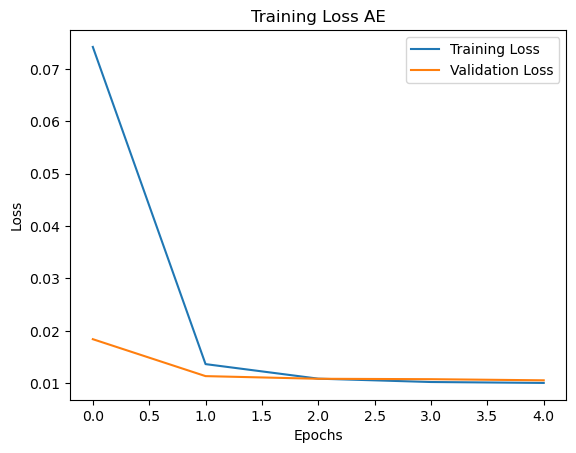

In [23]:
# plot the training a val loss over the epochs fro the naive autoencoder
plt.plot(history_ae.history['loss'], label='Training Loss')
plt.plot(history_ae.history['val_loss'], label='Validation Loss')
# Add labels and title
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Loss AE')

# Add legend
plt.legend()

# Display the plot
plt.show()

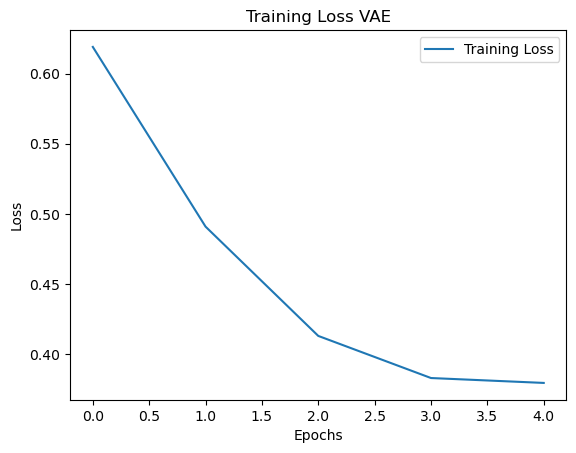

In [24]:
"""

#variational loss training and validation loss
train_losses = [item[0] for item in history_vae]
val_losses = [item[1] for item in history_vae]
epochs = range(1, len(history_cae)+1)

plt.plot(epochs, train_losses, label='Training Loss')
plt.plot(epochs, val_losses, label='Validation Loss')
plt.title('Training and Validation Loss CAE')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

"""


# plot the training a val loss over the epochs fro the naive autoencoder
plt.plot(history_vae.history['loss'], label='Training Loss')
#plt.plot(history_vae.history['val_loss'], label='Validation Loss')
# Add labels and title
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Loss VAE')

# Add legend
plt.legend()

# Display the plot
plt.show()


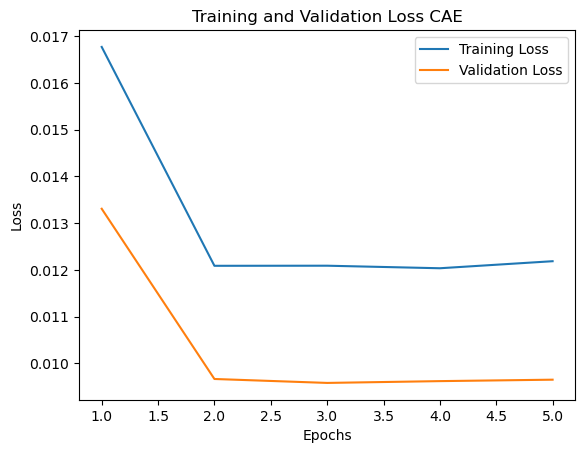

In [25]:
#contractive loss training and validation loss
train_losses = [item[0] for item in history_cae]
val_losses = [item[1] for item in history_cae]
epochs = range(1, len(history_cae)+1)

plt.plot(epochs, train_losses, label='Training Loss')
plt.plot(epochs, val_losses, label='Validation Loss')
plt.title('Training and Validation Loss CAE')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

25/25 [==============================] - 0s 3ms/step


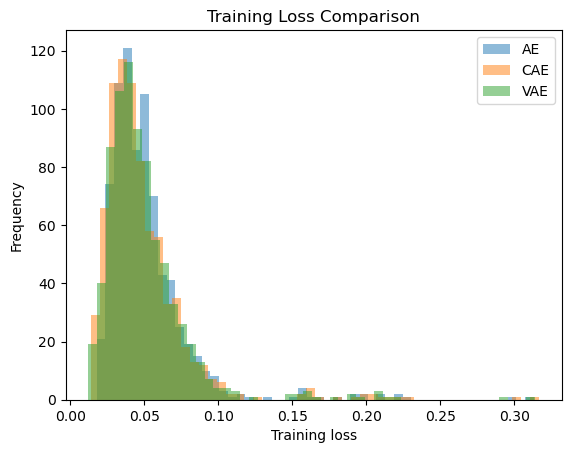

In [26]:
#MAE of the CAE over the number of samples 
cae_train_pred = cae.call(train_normal_data)
cae_mae_loss = np.mean(np.abs(cae_train_pred - train_normal_data), axis=1)

#MAE of the AE over the number of samples 
ae_train_pred = ae.predict(train_normal_data)
ae_mae_loss = np.mean(np.abs(ae_train_pred - train_normal_data), axis=1)

#MAE of the VAE over the number of samples 
vae_train_pred = vae.predict(train_normal_data)
vae_mae_loss = np.mean(np.abs(vae_train_pred - train_normal_data), axis=1)

# Plotting
plt.hist(ae_mae_loss, alpha= 0.5, label='AE', bins=50)
plt.hist(cae_mae_loss, alpha= 0.5, label='CAE', bins=50)
plt.hist(vae_mae_loss, alpha= 0.5, label='VAE', bins=50)

# Add labels and title
plt.xlabel('Training loss')
plt.ylabel('Frequency')
plt.title('Training Loss Comparison')

# Add legend
plt.legend()

# Display the plot
plt.show()

# Setting a threshold
In anomaly detection, a threshold is used to determine whether a sample is normal or anomalous based on its reconstruction error (i.e., the difference between the input and its reconstruction).

The threshold is typically set by selecting a value such that any sample with a reconstruction error above the threshold is classified as an anomaly, while any sample with a reconstruction error below the threshold is classified as normal. To come up with said thrashold we're going to take the mean and standard deviation of the residuals, and cosnidering a number of standard deviations away from the mean we're gonna find a threshold. 
The threshold needs to be set on the reconstruction for the training and not for the test as that would introduce some information on the underlying distribution of the data.

In [27]:
with open(os.devnull, 'w') as devnull, contextlib.redirect_stdout(devnull):

    deviations_threshold_ae = ae.find_best_deviations_threshold(x_train=train_normal_data, x_test=x_test, y_test=y_test)
    deviations_threshold_cae = cae.find_best_deviations_threshold(x_train=train_normal_data, x_test=x_test, y_test=y_test)
    deviations_threshold_vae = vae.find_best_deviations_threshold(x_train=train_normal_data, x_test=x_test, y_test=y_test)

In [28]:
#getting 
predictions_ae = ae.find_anomalies(x_test, deviations_threshold_ae)

#looking at the metrics for anomaly detection so far
ae.classification_metrics(y_test, predictions_ae, printing=True)

7/7 [==============================] - 0s 4ms/step
Accuracy: 0.7800
Precision: 0.0698
Recall: 0.4286
F1-Score: 0.1200
Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.79      0.87       193
           1       0.07      0.43      0.12         7

    accuracy                           0.78       200
   macro avg       0.52      0.61      0.50       200
weighted avg       0.94      0.78      0.85       200



In [29]:
#getting the predictions
predictions_cae = cae.find_anomalies(x_test, deviations_threshold_cae)

#looking at the metrics for anomaly detection so far
cae.classification_metrics(y_test, predictions_cae, printing=True)

Accuracy: 0.9500
Precision: 0.2000
Recall: 0.1429
F1-Score: 0.1667
Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.98      0.97       193
           1       0.20      0.14      0.17         7

    accuracy                           0.95       200
   macro avg       0.58      0.56      0.57       200
weighted avg       0.94      0.95      0.95       200



In [30]:
#getting the predictions
predictions_vae = vae.find_anomalies(x_test, deviations_threshold_cae)

#looking at the metrics for anomaly detection so far
vae.classification_metrics(y_test, predictions_vae, printing=True)

7/7 [==============================] - 0s 16ms/step
Accuracy: 0.9500
Precision: 0.2000
Recall: 0.1429
F1-Score: 0.1667
Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.98      0.97       193
           1       0.20      0.14      0.17         7

    accuracy                           0.95       200
   macro avg       0.58      0.56      0.57       200
weighted avg       0.94      0.95      0.95       200



# Performance 

Here we're going to take into consideration some metrics, with their relevant visualization, of the models' performance in the anomaly detectino task. 
As first step we're so going to look into the ROC curve, that is a plot of the "False positive rate" against the "True positive rate". The curve therefore aims at 
describing the strength of a classifier, such that the more the curve appriaches the top left corner the strongest the method is. While instead if the curve approaches the 
line y = x, or the corss-section of the plane, the more the classifier approaches a random one. 

In [31]:
def plot_ROC(y_test, predictions, name):

    # find the roc curve for the actual target values and the predictions
    fpr, tpr, _ = roc_curve(y_test, predictions)
    roc_auc = auc(fpr, tpr)

    #finding the Youden's J statistic, it's a metric that describes the power of classifier
    #where 0 is random guesser and 1 is a perfect classifier
    j_statistic = tpr - fpr
    print("the j_statistic is " + str(j_statistic[1]))

    #plotting the roc curve with the best trehsold against the random predictor
    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (AUC = %0.2f)' % roc_auc)
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve ' + name)
    plt.legend(loc="lower right")
    plt.show()


the j_statistic is 1.0


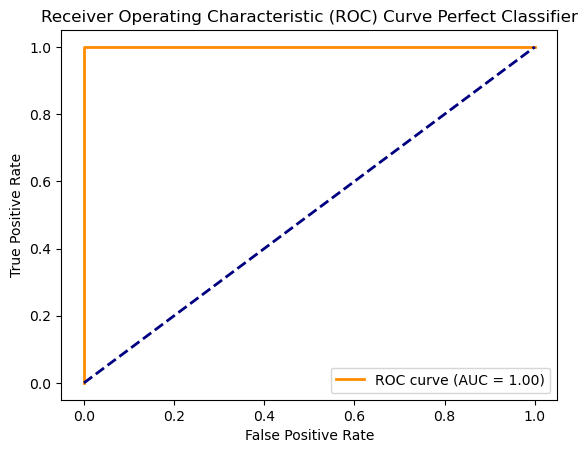

In [32]:
plot_ROC(y_test=y_test, predictions=y_test, name="Perfect Classifier")

the j_statistic is 0.22131754256106587


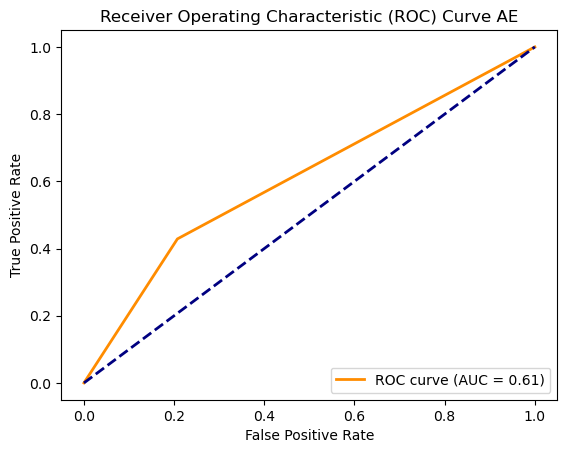

In [33]:
plot_ROC(y_test=y_test, predictions=predictions_ae, name="AE")

the j_statistic is 0.12213175425610658


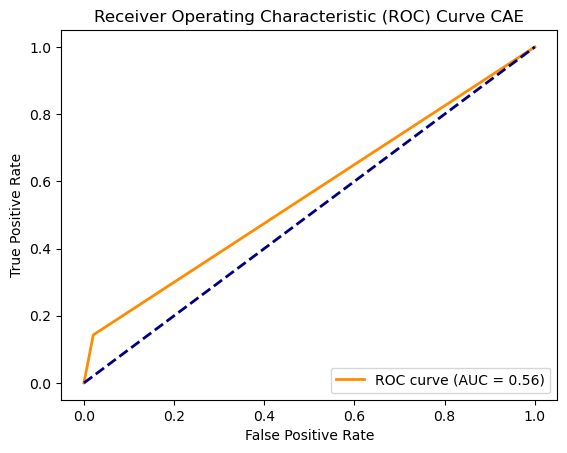

In [34]:
plot_ROC(y_test=y_test, predictions=predictions_cae, name="CAE")

the j_statistic is 0.12213175425610658


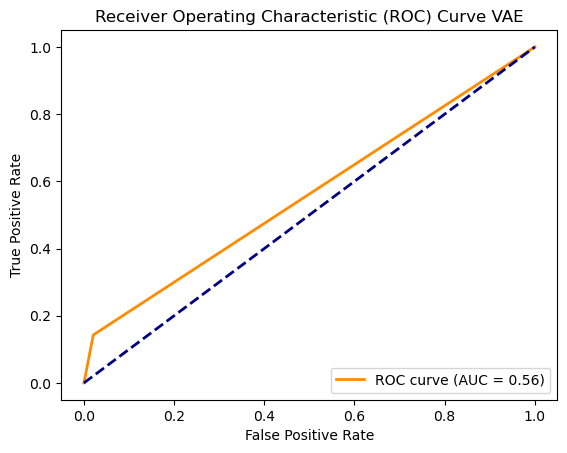

In [35]:
plot_ROC(y_test=y_test, predictions=predictions_vae, name="VAE")

### Precision recall curve

This type of plot is made to better understand the performance of the models, given an high class imbalance. Precision indicates the proportion of correct positive identifications. Recall instead the proportion of actual positives that has been identified correctly. A perfect classifier is a squashed against the top right corner. A no-skill model will instead have a precision equal to the % of the positive class. 

https://analyticsindiamag.com/complete-guide-to-understanding-precision-and-recall-curves/

In [36]:
def pr_curve(y_true, predictions, name):

    precision, recall, _ = precision_recall_curve(y_true, predictions)
    #find the no_skill classifier line
    no_skill_precision = np.sum(y_true) / len(y_true)

    # plot the precision-recall curve
    plt.plot(recall, precision, color="darkorange")
    plt.axhline(y=no_skill_precision, color='navy', linestyle='--', label='No Skill')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve ' + name)
    plt.show()

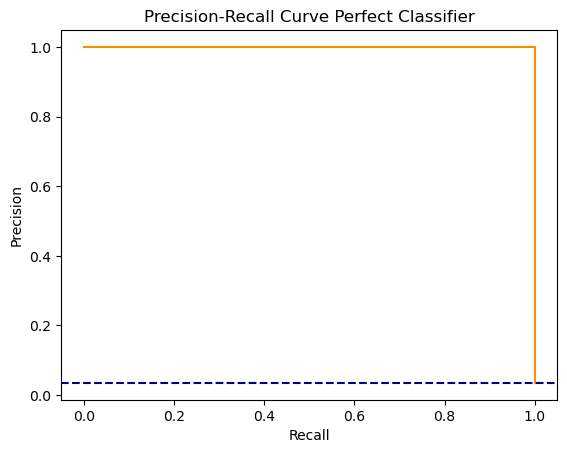

In [37]:
pr_curve(y_true=y_test, predictions=y_test, name="Perfect Classifier")

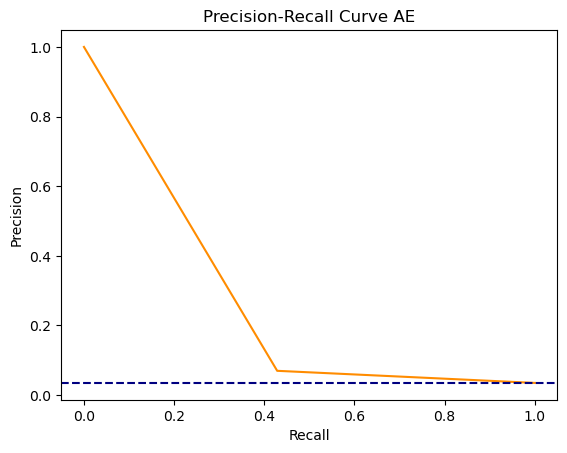

In [38]:
pr_curve(y_test, predictions_ae, name="AE")

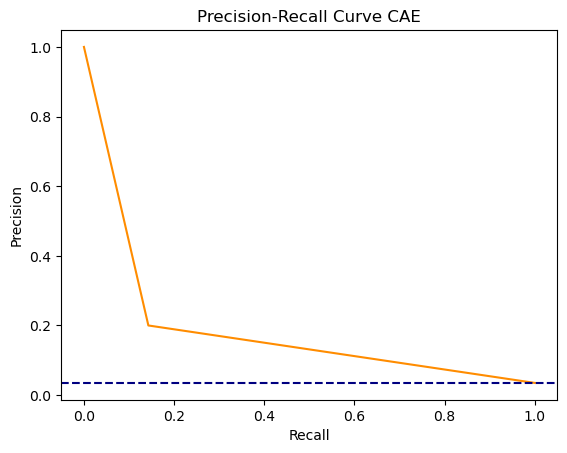

In [39]:
pr_curve(y_test, predictions_cae, name="CAE")

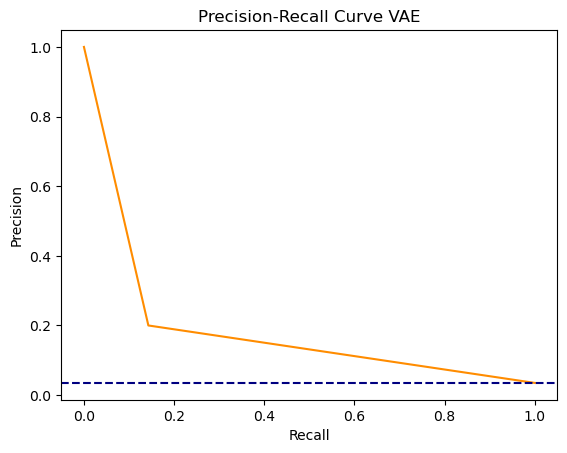

In [40]:
pr_curve(y_test, predictions_vae, name="VAE")

### Latent space plot.

Here we investigate how the ghost and normal samples are separated by the different models in the latent space. Eventually we would like to have the ghost tracks clustered together and so the normal ones. The normal tracks will be shown in green and the ghost tracks in red. 

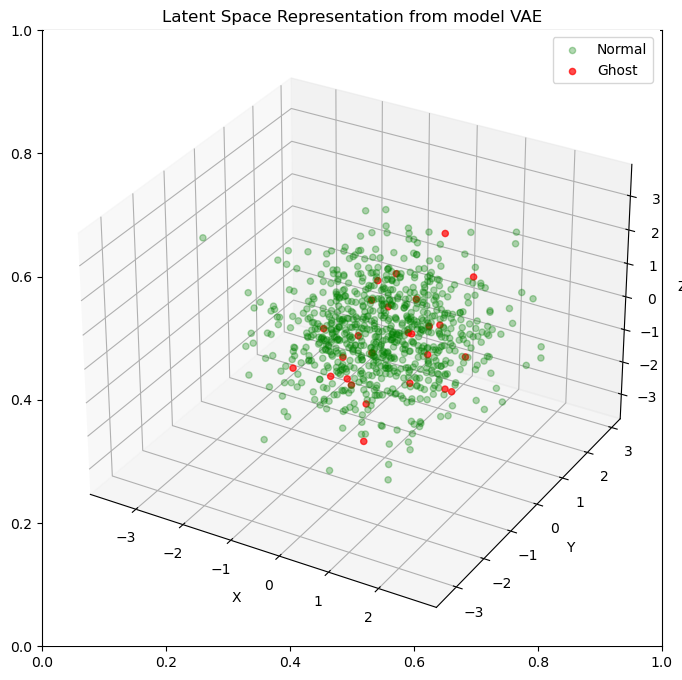

In [41]:
def plot_latent(name, model):
    
    data = tf.convert_to_tensor(x_train)
    latent_representation = model.encode(data)

    #different models have different ways of outputting the encoded data
    if tf.is_tensor(latent_representation):
        latent_representation = latent_representation.numpy()


    #accessing the value coordinates for the encoded data
    X = latent_representation[:,0]
    y = latent_representation[:,1]
    z = latent_representation[:,2]
    
    #plotting the data points in a 3D space
    #the green points correspond to normal instances
    #the red points correspond to the anomlaous data
    fig, ax = plt.subplots(figsize=(8, 8))
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(X[y_train==0], y[y_train==0], z[y_train==0], c='g', alpha=0.3, label='Normal')
    ax.scatter(X[y_train==1], y[y_train==1], z[y_train==1], c='r', alpha=0.7, label='Ghost')

    # labeling
    ax.legend(loc='best')
    ax.set_title('Latent Space Representation from model ' + name)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')

    # saving & displaying
    #plt.savefig('latent_representation_3d');
    plt.show()

plot_latent("VAE", vae)

25/25 [==============================] - 0s 4ms/step


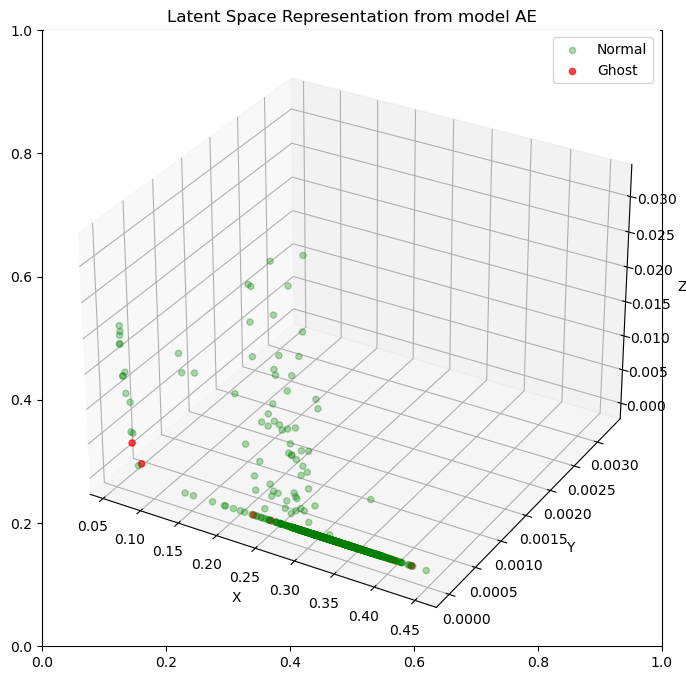

In [42]:
plot_latent("AE", ae)

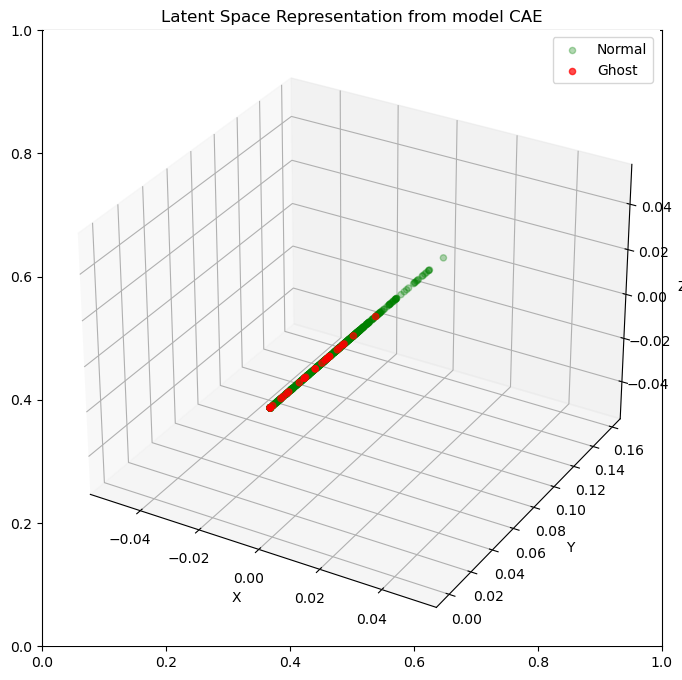

In [43]:
plot_latent("CAE", cae)

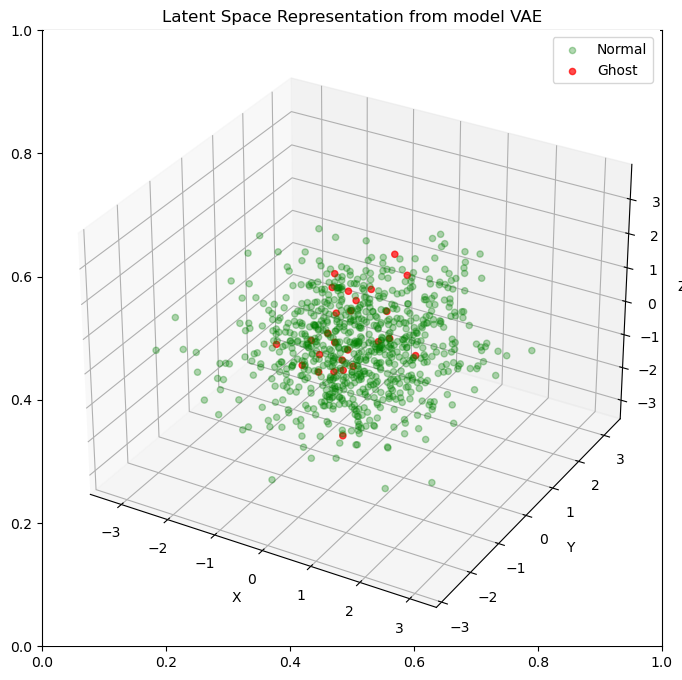

In [44]:
plot_latent("VAE", vae)

### Reconstruction error 

Here I'm plotting the reconstruction error distribution of the different methods so to have a overview of their "strength" and point out eventual discrepancies.

In [45]:
def plot_reconstruction_error(errors): 
    
    normal = errors[y_test==0]
    ghost = errors[y_test==1]

    _, ax = plt.subplots(figsize=(8,8))

    ax.hist(normal, bins=50, density=True, label="Normal", alpha=0.6)
    ax.hist(ghost, bins=50, density=True, label="Ghost", alpha=0.6)
    ax.set_xlabel("Frequency")
    ax.set_ylabel("Reconstruction loss")

    plt.title("(Normalized) Distribution of the Reconstruction Loss")
    
    plt.legend()
    plt.show()

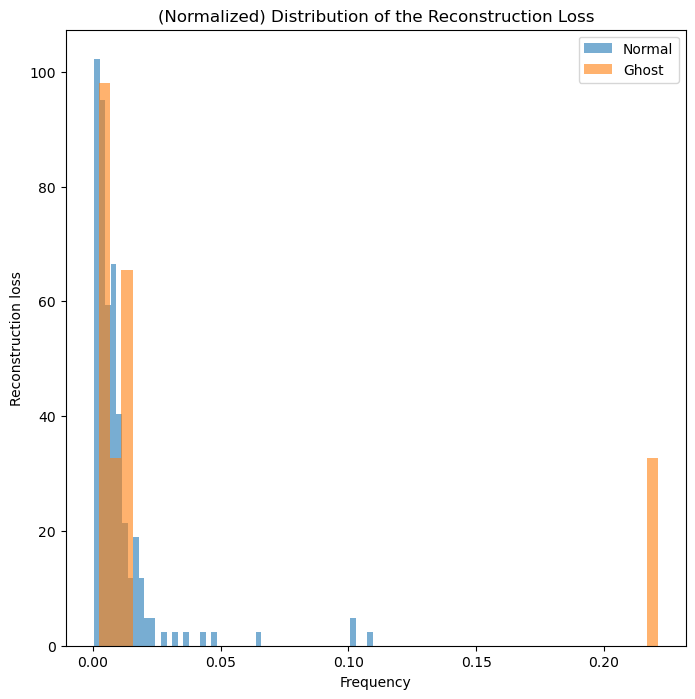

In [46]:
reconstruction_ae = ae.call(x_test)
mse = np.mean(np.power(x_test - reconstruction_ae, 2), axis=1)
plot_reconstruction_error(mse)

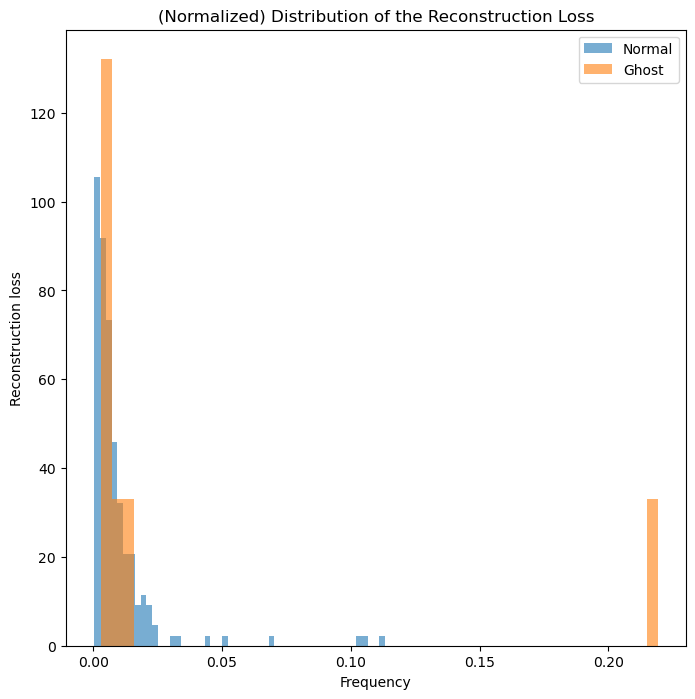

In [47]:
reconstruction_cae = cae.call(x_test)
mse = np.mean(np.power(x_test - reconstruction_cae, 2), axis=1)
plot_reconstruction_error(mse)

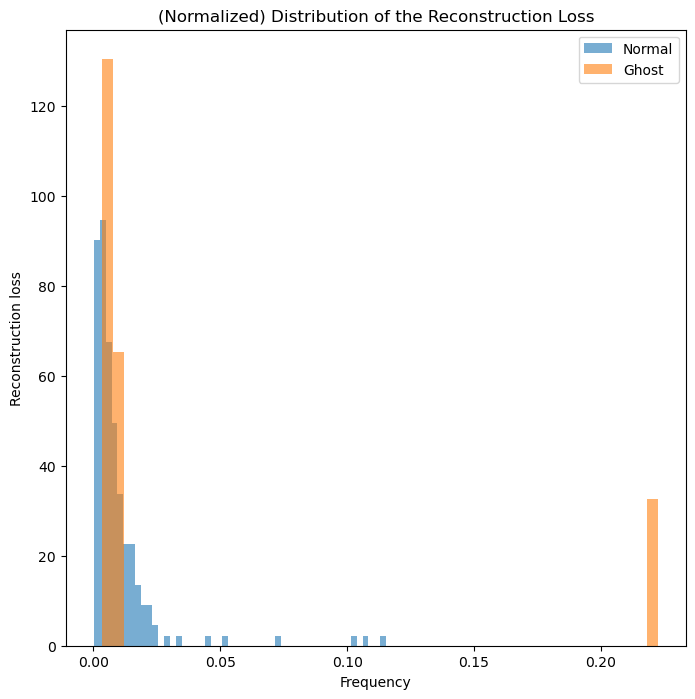

In [48]:
reconstruction_vae = vae.call(x_test)
mse = np.mean(np.power(x_test - reconstruction_vae, 2), axis=1)
plot_reconstruction_error(mse)

# ALAD
#### First we're gonna transfer the weights of the encoder part of the autoencoder to the generator of the ALAD

In [49]:
from models.alad.ALAD import ALAD
from sklearn.metrics import accuracy_score


latent_dim = train_normal_data.shape[1]
alad = ALAD(input_dim=train_normal_data.shape[1], latent_dim=latent_dim, learning_rate=0.003)

# the model needs to be trained on the normal data to learn the underlying distribution
alad.train(train_normal_data, epochs=5, batch_size=64)

predictions = alad.predict(x_test)


# here we're relying on a threshold set just based on the percentile
threshold = alad.find_best_deviations_threshold(train_normal_data, x_test, y_test)


predictions = np.where(predictions > threshold, 1, 0)

#print the accuracy and the roc
accuracy = accuracy_score(y_test, predictions)
print('Accuracy of anomaly detection: {:.2f}%'.format(accuracy * 100))

Epoch: 1,  Encoder Loss: 35.32607650756836, Generator Loss: 35.32693099975586, Disc_xx Loss: 2.8985562324523926, Disc_xz Loss: 0.001968570752069354, Disc_zz Loss: 0.45108562707901
Epoch: 2,  Encoder Loss: 24.77494239807129, Generator Loss: 24.7747859954834, Disc_xx Loss: 1.3453525304794312, Disc_xz Loss: 0.00015815216465853155, Disc_zz Loss: 0.044026151299476624
Epoch: 3,  Encoder Loss: 24.09316635131836, Generator Loss: 24.090503692626953, Disc_xx Loss: 0.920840322971344, Disc_xz Loss: 0.002663359511643648, Disc_zz Loss: 0.008507564663887024
Epoch: 4,  Encoder Loss: 34.86785888671875, Generator Loss: 34.86766815185547, Disc_xx Loss: 0.07515820860862732, Disc_xz Loss: 0.00019054723088629544, Disc_zz Loss: 0.0013430672697722912
Epoch: 5,  Encoder Loss: 49.96965789794922, Generator Loss: 49.96940612792969, Disc_xx Loss: 0.4280056655406952, Disc_xz Loss: 0.0002520564594306052, Disc_zz Loss: 0.031125087291002274
Accuracy of anomaly detection: 3.50%


Accuracy: 0.0350
Precision: 0.0350
Recall: 1.0000
F1-Score: 0.0676
Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       193
           1       0.04      1.00      0.07         7

    accuracy                           0.04       200
   macro avg       0.02      0.50      0.03       200
weighted avg       0.00      0.04      0.00       200

the j_statistic is 0.0


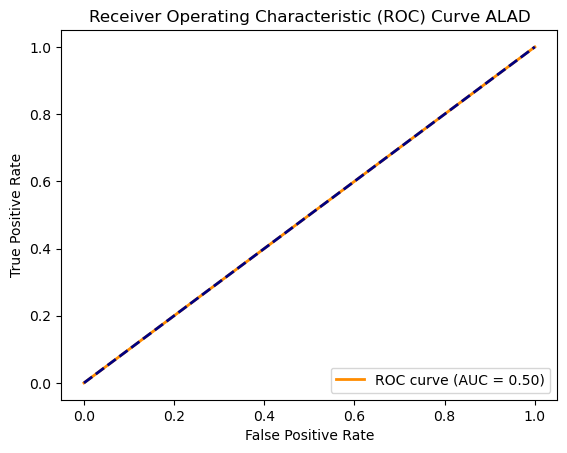

In [50]:
alad.classification_metrics(y_test, predictions, printing=True)
plot_ROC(y_test=y_test, predictions=predictions, name="ALAD")

# Isolation forest

Precision: 0.04
Recall: 1.0
F1-score: 0.07692307692307693
ROC AUC: 0.486328125
the j_statistic is 0.0


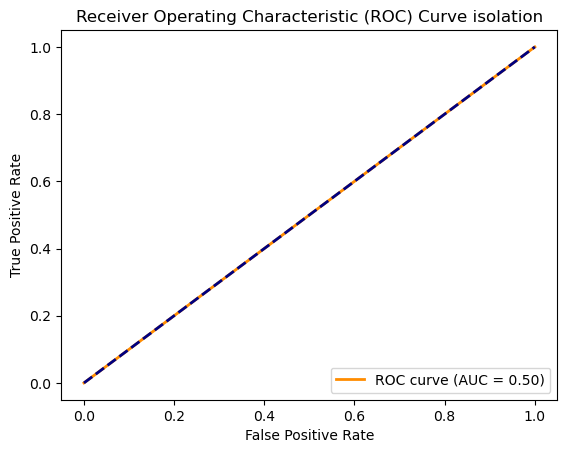

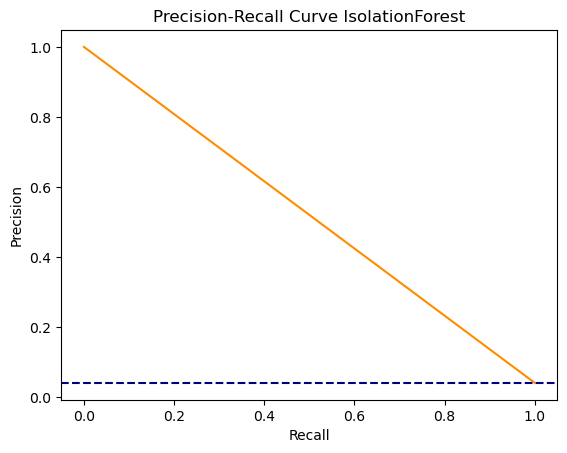

In [51]:
#this is an unsupervised learning method,
#in fact it is fed both normal and anomalous data
#during the training phase it learns from both normal and anomalous

from sklearn.ensemble import IsolationForest

X = df.drop(target_feature, axis=1)
y = df[target_feature]

X_train, X_test, y_train, y_test = train_test_split(X.values, y.values, test_size=0.2, random_state=42)


x_train = (X_train - X_train.mean()) / X_train.std()
x_test = (x_test - X_train.mean()) / X_train.std()

#now moving the data to a fixed range of values 
scaler = MinMaxScaler()

x_train = scaler.fit_transform(x_train)
x_test = scaler.fit_transform(x_test)

# trainig phase
clf = IsolationForest(n_estimators=10000, max_samples='auto', contamination=0.2, random_state=42)
clf.fit(x_train)

anomaly_scores = clf.decision_function(x_test)


y_pred = clf.predict(x_test)
y_pred = [1 if pred == -1 else 0 for pred in y_pred]


precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, anomaly_scores)

print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)
print("ROC AUC:", roc_auc)


plot_ROC(y_test, y_pred, "isolation")
pr_curve(y_test, y_pred, name="IsolationForest")

# One-class SVM

the j_statistic is 0.0


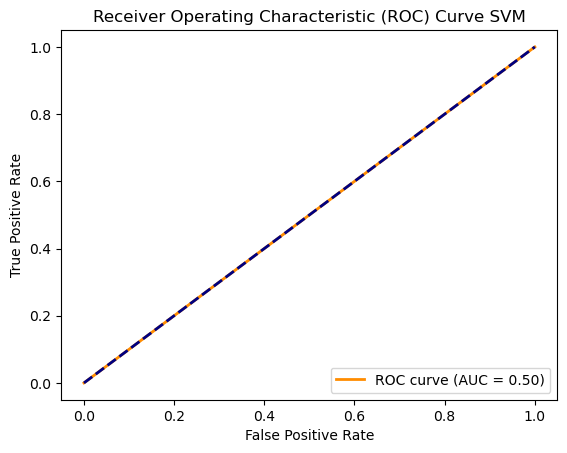

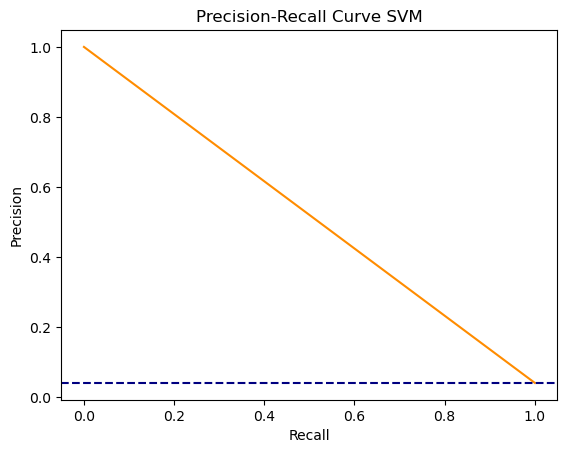

In [52]:

from sklearn import svm

# train the one class support vector machine
# nu specifies the upper bound on the tracks to be 
# classified as anomalies, it's a percentage 
# gamma controls the "smoothness" of the decision curve
# smaller gamma implies less overfitting but also lack of complexity...
clf = svm.OneClassSVM(nu=0.1, kernel="rbf", gamma=0.9)
clf.fit(train_normal_data)

# predict if the test instaces are anomalies or not
#Returns -1 for outliers and 1 for inliers.
y_pred = clf.predict(x_test)  


y_pred = [1 if pred == -1 else 0 for pred in y_pred]


# find the ROC curve 
plot_ROC(y_test, y_pred, "SVM")
pr_curve(y_test, y_pred, name="SVM")


# Ensemble classifier

Given none of the above methods has shown high performance, the last chance is to have them combined.

the j_statistic is -0.026041666666666668


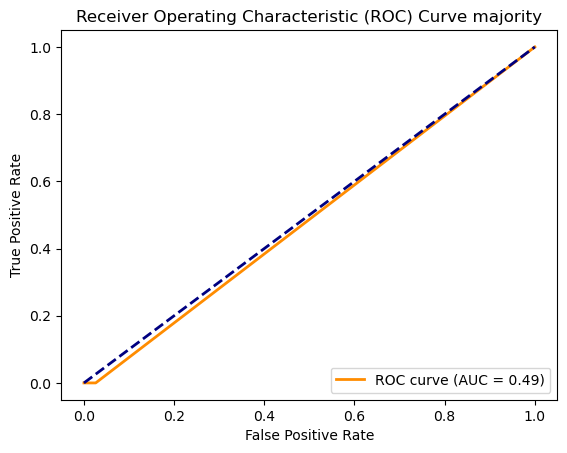

In [53]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression


#Majority voting
final_array = np.where((predictions_ae + predictions_cae + predictions_vae) >= 2, 1, 0)

plot_ROC(y_test=y_test, predictions=final_array, name="majority")

the j_statistic is -0.026041666666666668


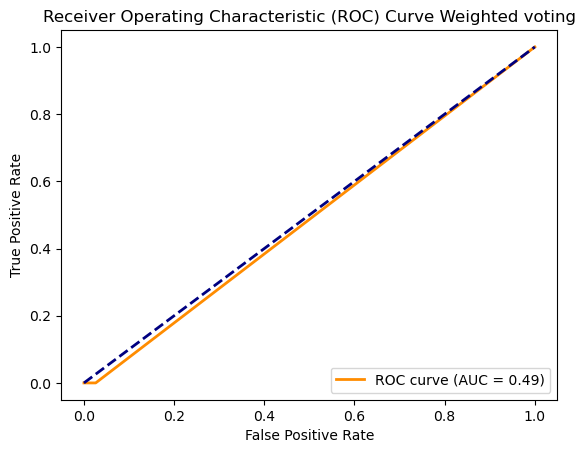

In [54]:
model_predictions = [predictions_ae, predictions_cae, predictions_vae]

auc_ae= roc_auc_score(y_test, predictions_ae)
auc_cae= roc_auc_score(y_test, predictions_cae)
auc_vae= roc_auc_score(y_test, predictions_vae)

weights = [auc_ae, auc_cae, auc_vae]

weights /= np.sum(weights)
final_prediction = np.average(model_predictions, axis=0, weights=weights)

#if a value is bigger then 0.5 the model will predict an anomaly 
final_prediction = np.round(final_prediction).astype(int)

plot_ROC(y_test=y_test, predictions=final_prediction, name="Weighted voting")